# 03 — Model evaluation

**Research question:** how accurate are our pre-match predictions compared with actual match results?

This notebook answers it with a **walk-forward backtest**: we pretend to use each model live from
the start of 2019/20 until today. Before every matchday, every model is retrained on all matches played
*before* that day, then predicts that day's matches. No prediction ever sees its own result or anything later.

We then measure the predictions with three scoring rules (lower = better for all three):

| Score | What it measures | Always 1/3 scores |
|---|---|---|
| **Log loss** | −log(probability given to what happened). Punishes confident mistakes hard. | 1.099 |
| **Brier score** | Squared distance between the probabilities and what happened. | 0.667 |
| **RPS** | Like Brier, but respects the order home win → draw → away win: predicting a draw when the home team won is "less wrong" than predicting an away win. The standard score for football. | ≈ 0.24 (depends on the draw share) |

Plus **calibration**: when the model says 40%, does it happen about 40% of the time?

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import PROCESSED_DIR, load_processed
from src.evaluation import (CLASSES, calibration_table, paired_difference, probs_of, rps,
                            score_table, walk_forward_backtest)
from src.models import (LOGISTIC_FEATURES, fit_baseline_before, fit_logistic_before,
                        fit_poisson_before)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
COLORS = {"Baseline": "#a0aec0", "Logistic": "#2b6cb0", "Poisson": "#c05621",
          "Logistic (xG only)": "#38a169", "Logistic (results only)": "#805ad5"}

## 0. Run the tests first

In [2]:
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], cwd=PROJECT_ROOT,
                        capture_output=True, text=True)
print(result.stdout[-1500:] or result.stderr[-1500:])

........................................................................ [ 93%]
.....                                                                    [100%]
77 passed in 3.86s



## 1. The models in the backtest

The three Stage 2 models, plus **feature-group variants** of the logistic model. They answer two questions:

- the "especially xG" part of the project: does knowing a team's recent xG help more than knowing its recent results?
- the league-table question: is it enough to know which team is higher in the table?

| Model | Inputs |
|---|---|
| Baseline | nothing about the teams; historical share of H/D/A |
| Logistic | all 9 differences: 8 last-5 form differences + season points per game |
| Poisson | all 27 home, away and difference features → expected goals → H/D/A |
| Logistic (xG only) | last-5 xG created, xG conceded, venue xG difference |
| Logistic (results only) | last-5 goals scored, goals conceded, points, win rate, venue points per game |
| Logistic (form only) | the 8 last-5 form differences, no table (the model before the table feature was added) |
| Logistic (table only) | only the difference in season points per game |

In [3]:
XG_ONLY = ["xg_for_diff", "xg_against_diff", "venue_xgd_diff"]
RESULTS_ONLY = ["goals_for_diff", "goals_against_diff", "points_diff", "win_rate_diff", "venue_ppg_diff"]
FORM_ONLY = [f for f in LOGISTIC_FEATURES if f != "season_ppg_diff"]
TABLE_ONLY = ["season_ppg_diff"]

FITTERS = {
    "Baseline": fit_baseline_before,
    "Logistic": fit_logistic_before,
    "Poisson": fit_poisson_before,
    "Logistic (xG only)": lambda m, d: fit_logistic_before(m, d, features=XG_ONLY),
    "Logistic (results only)": lambda m, d: fit_logistic_before(m, d, features=RESULTS_ONLY),
    "Logistic (form only)": lambda m, d: fit_logistic_before(m, d, features=FORM_ONLY),
    "Logistic (table only)": lambda m, d: fit_logistic_before(m, d, features=TABLE_ONLY),
}
MAIN = ["Baseline", "Logistic", "Poisson"]

## 2. Run the walk-forward backtest

Backtest window: **1 July 2019 to today** (2019/20 to the 2026/27 matches played so far). The first
prediction is trained on three seasons (2016/17–2018/19), and the training set grows every matchday.
This takes about half a minute.

Note: the regularisation strengths were chosen in notebook 02 using 2024/25, which is inside this
window. The log-loss curves there were flat, so the effect on these results is negligible.

In [4]:
features = load_processed()
BACKTEST_START = "2019-07-01"

backtest = walk_forward_backtest(features, FITTERS, BACKTEST_START)
path = PROCESSED_DIR / "backtest_predictions.csv"
backtest.to_csv(path, index=False)
print(f"Saved {len(backtest)} rows to {path.relative_to(PROJECT_ROOT)}")
backtest.head()

  100/843 matchdays done


  200/843 matchdays done


  300/843 matchdays done


  400/843 matchdays done


  500/843 matchdays done


...

  700/843 matchdays done


  800/843 matchdays done


Backtest done: 2666 matches on 843 matchdays, 7 models.


Saved 18662 rows to data/processed/backtest_predictions.csv


,date,season,home_team,away_team,home_goals,away_goals,result,model,p_H,p_D,p_A,n_train
0,2019-08-10 12:30:00,1920,West Ham,Manchester City,0,5,A,Baseline,0.475022,0.222612,0.302366,1141
1,2019-08-10 15:00:00,1920,Burnley,Southampton,3,0,H,Baseline,0.475022,0.222612,0.302366,1141
2,2019-08-10 15:00:00,1920,Crystal Palace,Everton,0,0,D,Baseline,0.475022,0.222612,0.302366,1141
3,2019-08-10 15:00:00,1920,Watford,Brighton,0,3,A,Baseline,0.475022,0.222612,0.302366,1141
4,2019-08-10 12:30:00,1920,West Ham,Manchester City,0,5,A,Logistic,0.237146,0.206357,0.556497,1044


## 3. Overall scores

Every model is scored on exactly the same matches.

In [5]:
results, _ = probs_of(backtest, "Baseline")
predictions = {name: probs_of(backtest, name)[1] for name in FITTERS}

uniform = np.full((len(results), 3), 1 / 3)
scores = score_table(results, {"Uniform 1/3": uniform, **predictions})
print(f"{len(results)} matches, {backtest['date'].min().date()} to {backtest['date'].max().date()}")
scores.round(4)

2666 matches, 2019-08-10 to 2026-10-11


,log loss,Brier,RPS,accuracy
Uniform 1/3,1.0986,0.6667,0.2381,0.4332
Baseline,1.0713,0.6487,0.2335,0.4332
Logistic,0.9967,0.5936,0.2063,0.5195
Poisson,0.9945,0.5929,0.2062,0.5203
Logistic (xG only),1.0049,0.5994,0.2094,0.5135
Logistic (results only),1.0232,0.6135,0.2160,0.4996
Logistic (form only),1.0061,0.6002,0.2097,0.5131
Logistic (table only),1.0125,0.6045,0.2114,0.5180


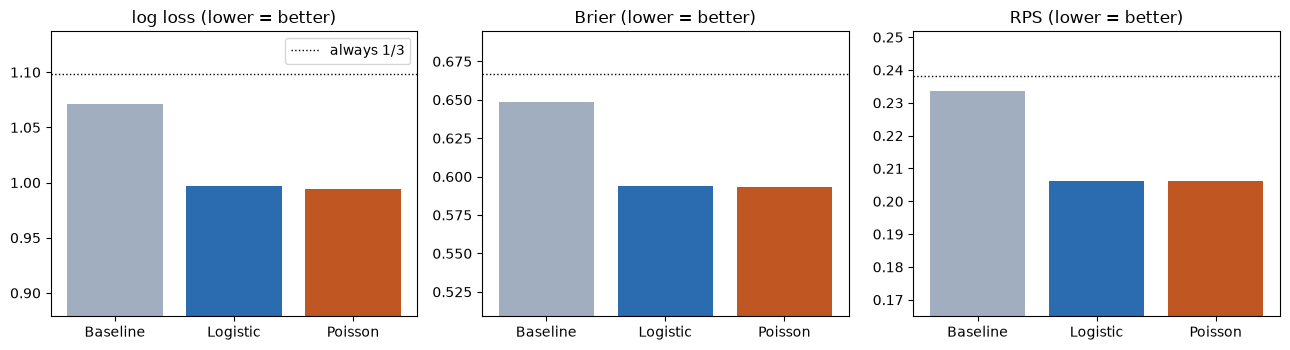

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metric in zip(axes, ["log loss", "Brier", "RPS"]):
    vals = scores.loc[MAIN, metric]
    ax.bar(vals.index, vals.values, color=[COLORS[m] for m in vals.index])
    ax.axhline(scores.loc["Uniform 1/3", metric], color="black", ls=":", lw=1, label="always 1/3")
    pad = (vals.max() - vals.min()) * 1.5
    ax.set_ylim(vals.min() - pad, scores.loc["Uniform 1/3", metric] + pad / 3)
    ax.set_title(f"{metric} (lower = better)")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

## 4. Are the differences real or luck?

Each model is compared with another **on the same matches** (a paired comparison), which removes
match-to-match difficulty. The table shows the average per-match difference with a 95% interval.
**Negative = the first model is better.** If the interval includes 0, the data cannot separate the two.

In [7]:
pairs = [
    ("Logistic", "Baseline"),
    ("Poisson", "Baseline"),
    ("Logistic", "Poisson"),
    ("Logistic (xG only)", "Logistic (results only)"),
    ("Logistic (form only)", "Logistic (table only)"),
    ("Logistic", "Logistic (table only)"),
    ("Logistic", "Logistic (form only)"),
]
rows = []
for a, b in pairs:
    for metric in ["RPS", "log loss"]:
        d = paired_difference(results, predictions[a], predictions[b], metric)
        rows.append({"comparison": f"{a}  vs  {b}", "metric": metric, **d,
                     "clear winner?": "yes" if d["ci high"] < 0 or d["ci low"] > 0 else "no"})
comparisons = pd.DataFrame(rows).set_index(["comparison", "metric"]).drop(columns="n")
comparisons.round(4)

mean diff  ci low  ci high clear winner?
comparison                                      metric                                            
Logistic  vs  Baseline                          RPS         -0.0273 -0.0324  -0.0221           yes
                                                log loss    -0.0746 -0.0900  -0.0592           yes
Poisson  vs  Baseline                           RPS         -0.0274 -0.0324  -0.0224           yes
                                                log loss    -0.0768 -0.0916  -0.0621           yes
Logistic  vs  Poisson                           RPS          0.0001 -0.0008   0.0010            no
                                                log loss     0.0022 -0.0014   0.0058            no
Logistic (xG only)  vs  Logistic (results only) RPS         -0.0066 -0.0098  -0.0034           yes
                                                log loss    -0.0183 -0.0278  -0.0087           yes
Logistic (form only)  vs  Logistic (table only) RPS         -0.0018 -0.0057   0.0022            no
                                                log loss    -0.0065 -0.0190   0.0061            no
Logistic  vs  Logistic (table only)             RPS         -0.0052 -0.0077  -0.0026           yes
                                                log loss    -0.0159 -0.0239  -0.0078           yes
Logistic  vs  Logistic (form only)              RPS         -0.0034 -0.0054  -0.0014           yes
                                                log loss    -0.0094 -0.0158  -0.0030           yes

### The league-table question

*"Why not just pick the team higher in the table?"* The simplest version of that rule: the team with more points per
game this season so far is predicted to win (on a tie, the home team). It uses the same leakage-safe numbers as the
`season_ppg` feature, so it never sees the result. It only names a winner, so it can be compared on accuracy only;
the "table only" model above is the same information turned into probabilities, so it can be scored properly.

In [8]:
bt_rows = backtest[backtest["model"] == "Baseline"].reset_index(drop=True)
keys = ["date", "home_team", "away_team"]
season_cols = features[keys + ["home_season_ppg", "away_season_ppg"]].copy()
season_cols["date"] = pd.to_datetime(season_cols["date"])
joined = bt_rows[keys + ["result"]].merge(season_cols, on=keys, how="left")
rule_pick = np.where(joined["away_season_ppg"] > joined["home_season_ppg"], "A", "H")
rule_acc = (rule_pick == joined["result"]).mean()

table_question = pd.DataFrame({
    "favourite won": {
        "Always pick the home team": (results == "H").mean(),
        "Pick the team higher in the table (rule)": rule_acc,
        "Logistic (table only)": scores.loc["Logistic (table only)", "accuracy"],
        "Logistic (form only)": scores.loc["Logistic (form only)", "accuracy"],
        "Logistic (form + table)": scores.loc["Logistic", "accuracy"],
    },
    "RPS": {
        "Always pick the home team": np.nan,
        "Pick the team higher in the table (rule)": np.nan,
        "Logistic (table only)": scores.loc["Logistic (table only)", "RPS"],
        "Logistic (form only)": scores.loc["Logistic (form only)", "RPS"],
        "Logistic (form + table)": scores.loc["Logistic", "RPS"],
    },
})
fav = predictions["Logistic"].argmax(axis=1)
model_pick = np.array(CLASSES)[fav]
disagree = model_pick != rule_pick
print(f"The table rule and the model pick the same outcome in {1 - disagree.mean():.0%} of matches.")
print(f"Where they disagree ({disagree.sum()} matches): model right {(model_pick == results.to_numpy())[disagree].mean():.0%}, "
      f"table rule right {(rule_pick == results.to_numpy())[disagree].mean():.0%}.")
table_question.round(4)

The table rule and the model pick the same outcome in 81% of matches.
Where they disagree (503 matches): model right 41%, table rule right 33%.


,favourite won,RPS
Always pick the home team,0.4332,NaN
Pick the team higher in the table (rule),0.5053,NaN
Logistic (table only),0.5180,0.2114
Logistic (form only),0.5131,0.2097
Logistic (form + table),0.5195,0.2063


## 5. Scores per season

Does the advantage hold every season, or is it driven by one lucky year? 2026/27 is only partly played,
so its score is noisy.

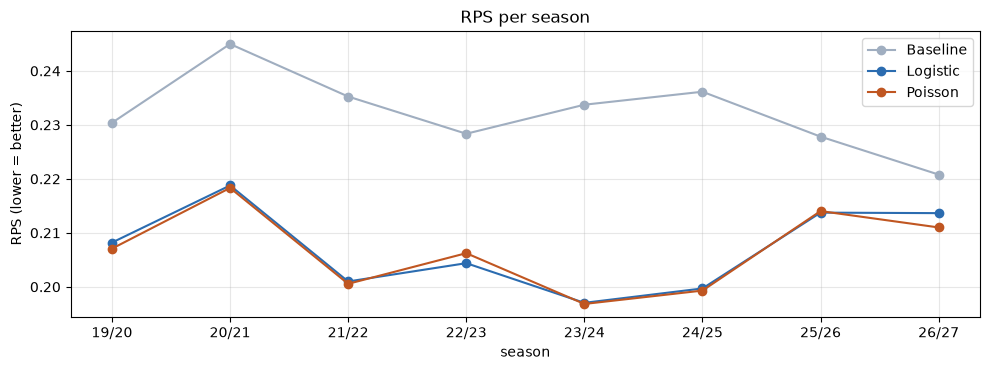

model,matches,Baseline,Logistic,Poisson,Logistic (xG only),Logistic (results only),Logistic (form only),Logistic (table only)
season,,,,,,,,
1920,362,0.2304,0.2082,0.2071,0.2114,0.2116,0.2106,0.2100
2021,374,0.2450,0.2188,0.2183,0.2206,0.2289,0.2213,0.2280
2122,374,0.2353,0.2010,0.2006,0.2012,0.2117,0.2030,0.2090
2223,374,0.2284,0.2044,0.2062,0.2070,0.2169,0.2085,0.2066
2324,374,0.2337,0.1970,0.1968,0.2047,0.2059,0.2031,0.2002
2425,374,0.2361,0.1997,0.1993,0.2025,0.2175,0.2041,0.2078
2526,380,0.2278,0.2137,0.2140,0.2167,0.2188,0.2157,0.2170
2627,54,0.2208,0.2136,0.2110,0.2222,0.2186,0.2203,0.2209


In [9]:
per_season = (backtest.groupby(["season", "model"])
              .apply(lambda g: rps(g["result"], g[["p_H", "p_D", "p_A"]].to_numpy()), include_groups=False)
              .unstack()[list(FITTERS)])
per_season.insert(0, "matches", backtest[backtest["model"] == "Baseline"].groupby("season").size())

fig, ax = plt.subplots(figsize=(10, 3.8))
labels = [f"{str(s)[:2]}/{str(s)[2:]}" for s in per_season.index]
for name in MAIN:
    ax.plot(labels, per_season[name], marker="o", color=COLORS[name], label=name)
ax.set_ylabel("RPS (lower = better)")
ax.set_xlabel("season")
ax.set_title("RPS per season")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
per_season.round(4)

**2020/21** was played almost entirely without crowds (COVID-19). Home advantage nearly disappeared that
season, so the baseline, which leans heavily on "home teams win 45%", had its worst year.

In [10]:
home_share = features.groupby("season")["result"].apply(lambda r: (r == "H").mean())
print("Share of home wins per season:")
print(home_share.round(3).to_string())

Share of home wins per season:
season
1617    0.492
1718    0.455
1819    0.476
1920    0.453
2021    0.379
2122    0.429
2223    0.484
2324    0.461
2425    0.408
2526    0.426
2627    0.383


## 6. Calibration

For each outcome, matches are grouped by the predicted probability (0–10%, 10–20%, ...). In each group we
compare the **average prediction** with **how often it actually happened**. A well-calibrated model sits on
the diagonal. Point size shows how many matches are in the group. Groups with fewer than 20 matches are
left out of the plot because one or two results would swing them wildly; the tables below show every group.

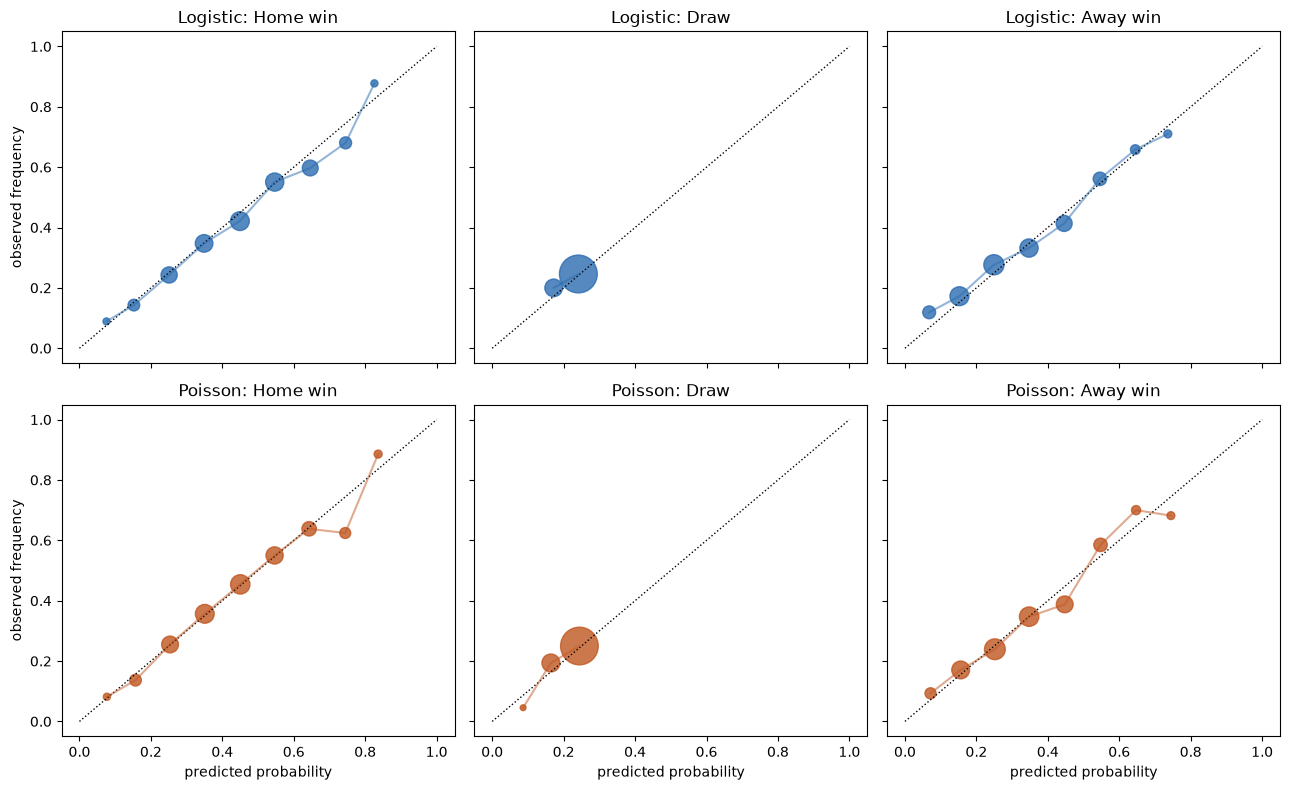

In [11]:
MIN_BIN = 20
fig, axes = plt.subplots(len(MAIN) - 1, 3, figsize=(13, 8), sharex=True, sharey=True)
for r, name in enumerate(["Logistic", "Poisson"]):
    for c, (outcome, label) in enumerate(zip(CLASSES, ["Home win", "Draw", "Away win"])):
        ax = axes[r, c]
        table = calibration_table(results, predictions[name], outcome)
        table = table[table["matches"] >= MIN_BIN]
        ax.plot([0, 1], [0, 1], color="black", ls=":", lw=1)
        ax.scatter(table["predicted"], table["observed"], s=table["matches"] / 3 + 10,
                   color=COLORS[name], alpha=0.8)
        ax.plot(table["predicted"], table["observed"], color=COLORS[name], alpha=0.5)
        ax.set_title(f"{name}: {label}")
        if r == 1:
            ax.set_xlabel("predicted probability")
        if c == 0:
            ax.set_ylabel("observed frequency")
plt.tight_layout()
plt.show()

In [12]:
for name in ["Logistic", "Poisson"]:
    print(f"\n{name}, home win:")
    print(calibration_table(results, predictions[name], "H").round(3).to_string())


Logistic, home win:
         predicted  observed  matches
0.0-0.1      0.076     0.089       45
0.1-0.2      0.152     0.143      182
0.2-0.3      0.251     0.243      379
0.3-0.4      0.349     0.347      452
0.4-0.5      0.449     0.421      520
0.5-0.6      0.547     0.551      485
0.6-0.7      0.646     0.597      360
0.7-0.8      0.745     0.680      194
0.8-0.9      0.826     0.878       49

Poisson, home win:
         predicted  observed  matches
0.0-0.1      0.077     0.082       49
0.1-0.2      0.157     0.137      183
0.2-0.3      0.254     0.255      408
0.3-0.4      0.351     0.356      519
0.4-0.5      0.450     0.454      555
0.5-0.6      0.546     0.550      431
0.6-0.7      0.643     0.638      293
0.7-0.8      0.744     0.624      157
0.8-0.9      0.836     0.886       70
0.9-1.0      0.902     1.000        1


### Draws

Football models often under-predict draws, so check: average predicted draw probability vs the actual share.
Note that draw predictions sit in a narrow range (mostly 20–30%). The models struggle to tell which
matches will be draws, which is typical for football and the main reason accuracy stays around 50%.

In [13]:
draw_check = pd.DataFrame({
    "avg predicted P(draw)": {n: p[:, 1].mean() for n, p in predictions.items() if n in MAIN},
    "lowest P(draw)": {n: p[:, 1].min() for n, p in predictions.items() if n in MAIN},
    "highest P(draw)": {n: p[:, 1].max() for n, p in predictions.items() if n in MAIN},
})
print(f"Actual draw share: {(results == 'D').mean():.3f}")
draw_check.round(3)

Actual draw share: 0.238


,avg predicted P(draw),lowest P(draw),highest P(draw)
Baseline,0.228,0.223,0.234
Logistic,0.230,0.106,0.342
Poisson,0.229,0.067,0.298


## 7. Confident predictions

When a model is very sure (top favourite ≥ 60%), how often is it right? This is calibration in plain words.

In [14]:
rows = []
for name in ["Logistic", "Poisson"]:
    p = predictions[name]
    top = p.max(axis=1)
    hit = (p.argmax(axis=1) == results.map(CLASSES.index).to_numpy())
    for lo, hi in [(0.33, 0.45), (0.45, 0.6), (0.6, 0.75), (0.75, 1.0)]:
        mask = (top >= lo) & (top < hi)
        rows.append({"model": name, "favourite's probability": f"{lo:.0%}–{hi:.0%}",
                     "matches": int(mask.sum()), "avg predicted": top[mask].mean(),
                     "favourite won": hit[mask].mean()})
pd.DataFrame(rows).set_index(["model", "favourite's probability"]).round(3)

matches  avg predicted  favourite won
model    favourite's probability                                       
Logistic 33%–45%                      722          0.412          0.371
         45%–60%                     1145          0.521          0.518
         60%–75%                      635          0.665          0.619
         75%–100%                     164          0.790          0.799
Poisson  33%–45%                      808          0.409          0.390
         45%–60%                     1154          0.517          0.516
         60%–75%                      525          0.664          0.634
         75%–100%                     179          0.804          0.804

## 8. Summary

The cell below prints the main numbers for the report.

In [15]:
lp = comparisons.loc[("Logistic  vs  Poisson", "RPS")]
xr = comparisons.loc[("Logistic (xG only)  vs  Logistic (results only)", "RPS")]
print(f"Backtest: {len(results)} Premier League matches, {backtest['date'].min().date()} to {backtest['date'].max().date()}")
print()
for name in MAIN:
    s = scores.loc[name]
    print(f"{name:<9} log loss {s['log loss']:.4f}  Brier {s['Brier']:.4f}  RPS {s['RPS']:.4f}  accuracy {s['accuracy']:.1%}")
print()
print(f"Logistic vs Poisson RPS difference: {lp['mean diff']:+.4f} "
      f"(95% interval {lp['ci low']:+.4f} to {lp['ci high']:+.4f}) -> clear winner: {lp['clear winner?']}")
print(f"xG-only vs results-only RPS difference: {xr['mean diff']:+.4f} "
      f"(95% interval {xr['ci low']:+.4f} to {xr['ci high']:+.4f}) -> clear winner: {xr['clear winner?']}")

Backtest: 2666 Premier League matches, 2019-08-10 to 2026-10-11

Baseline  log loss 1.0713  Brier 0.6487  RPS 0.2335  accuracy 43.3%
Logistic  log loss 0.9967  Brier 0.5936  RPS 0.2063  accuracy 52.0%
Poisson   log loss 0.9945  Brier 0.5929  RPS 0.2062  accuracy 52.0%

Logistic vs Poisson RPS difference: +0.0001 (95% interval -0.0008 to +0.0010) -> clear winner: no
xG-only vs results-only RPS difference: -0.0066 (95% interval -0.0098 to -0.0034) -> clear winner: yes


### Findings

*Written from the backtest above. If you re-run with newer data, check the numbers still say the same.*

1. **Both models clearly beat the baseline** on all three scores, and the 95% intervals are far from 0.
   Knowing the teams' recent form and season record is genuinely useful.
2. **Logistic and Poisson are tied.** Their difference is far smaller than the uncertainty. They use
   the same information, and the different model structure makes no practical difference.
3. **Over the last 5 matches, xG beats results.** A model using only last-5 xG features clearly beats one using only
   last-5 goals, points and wins, and adding those results features to xG adds nothing. Over a short window, xG is a
   better guide to a team's strength than its results, because results contain more luck. This supports the project's
   focus on xG.
4. **The league table adds something recent form doesn't.** On its own, the table (season points per game) is about as
   good as last-5 form: the "form only" and "table only" models cannot be told apart. Combined, they are clearly better
   than either alone, in every season. The table measures quality over the whole season; form measures how a team is
   playing right now.
5. **"Just pick the team higher in the table" picks winners almost as often** (about 50.5% against the model's 52%),
   but it gives no probabilities and never allows for a draw. Where the rule and the model disagree, the model is right
   more often.
6. **Calibration is good.** When a model says 50% the outcome happens about 50% of the time. The biggest
   home favourites (70–80%) win less often than predicted, so the models are somewhat overconfident there.
7. **Draws are the weak spot.** The average draw probability matches the real draw share, but the models
   can barely tell *which* matches will be draws. Almost every prediction is 20–30% draw. This
   is the main reason accuracy stays around 50%.
8. **Improvement is real but modest.** Football is very random. Even a good model only lowers RPS from
   about 0.23 to 0.21. Bookmaker odds are the usual benchmark for "how good can it get"; we have no odds
   data, so comparing against them would be a natural next step.
9. **2020/21 (no crowds)** had far fewer home wins, which hurt the baseline most. The form-based models
   adapted better because they look at recent matches.

**Limitations:** one league; matches are treated as independent in the intervals; features ignore
injuries, transfers, managers and line-ups; teams new to the data have no predictions for their first 5 matches;
regularisation was chosen on 2024/25, which is inside the backtest window (minor effect); the table feature was
added after comparing alternatives on this same backtest, so its gain may be slightly optimistic. It is a single,
simple feature that helped in all 8 seasons, so the risk is small; the truly fresh test is future matches (notebook 04).